In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset


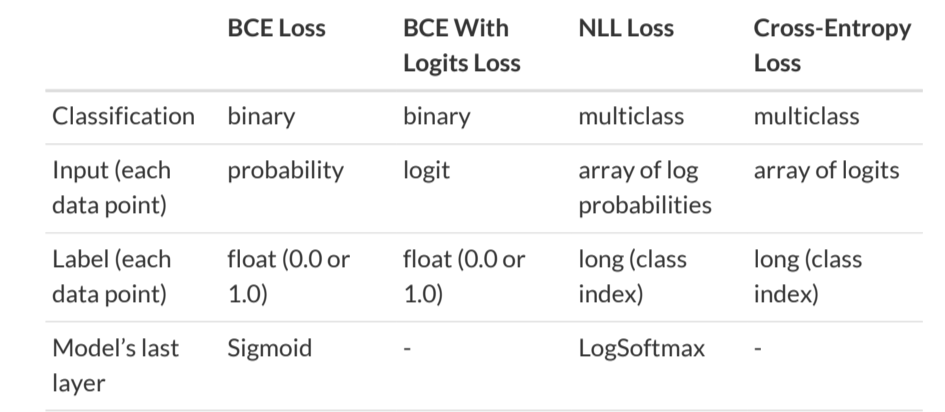

In [3]:
X,y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2)


In [3]:
X_test

array([[5.7, 2.8, 4.5, 1.3],
       [5.8, 2.7, 5.1, 1.9],
       [7.7, 2.6, 6.9, 2.3],
       [5.8, 2.8, 5.1, 2.4],
       [5.1, 3.5, 1.4, 0.2],
       [6.5, 3. , 5.2, 2. ],
       [4.8, 3. , 1.4, 0.3],
       [6.3, 2.9, 5.6, 1.8],
       [6. , 2.2, 5. , 1.5],
       [6.7, 3.1, 5.6, 2.4],
       [6.4, 2.8, 5.6, 2.2],
       [6.7, 3.3, 5.7, 2.1],
       [5.1, 3.7, 1.5, 0.4],
       [5. , 3.6, 1.4, 0.2],
       [6.7, 3.1, 4.4, 1.4],
       [4.4, 2.9, 1.4, 0.2],
       [5.7, 2.6, 3.5, 1. ],
       [5.2, 3.4, 1.4, 0.2],
       [6.7, 3. , 5. , 1.7],
       [5.1, 3.5, 1.4, 0.3],
       [4.8, 3.1, 1.6, 0.2],
       [6.9, 3.1, 5.4, 2.1],
       [5.8, 2.7, 3.9, 1.2],
       [6.3, 2.5, 4.9, 1.5],
       [6.8, 3.2, 5.9, 2.3],
       [6.3, 3.3, 4.7, 1.6],
       [5.5, 2.6, 4.4, 1.2],
       [6.3, 3.3, 6. , 2.5],
       [5.1, 3.8, 1.5, 0.3],
       [5.2, 4.1, 1.5, 0.1]])

In [4]:
y_test

array([1, 2, 2, 2, 0, 2, 0, 2, 2, 2, 2, 2, 0, 0, 1, 0, 1, 0, 1, 0, 0, 2,
       1, 1, 2, 1, 1, 2, 0, 0])

In [5]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(X_train)
X_train = sc.transform(X_train)
X_test = sc.transform(X_test)

In [7]:
# 转换为tensor
X_train_tensor = torch.as_tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.as_tensor(y_train, dtype=torch.int64)
X_test_tensor = torch.as_tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.as_tensor(y_test, dtype=torch.int64)
# 数据集
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
# 数据加载器
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)


In [8]:
# 定义模型
class Classification(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 32)
        self.fc2 = nn.Linear(32, 32)
        self.fc3 = nn.Linear(32, 3)

    def forward(self, x):
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        x = self.fc3(x)
        return x

In [9]:
# mini-batch training
def mini_batch_train(model, train_loader, optimizer, loss_fn):
    mini_batch_losses = []
    for x_batch, y_batch in train_loader:
        model.train()
        # step 1 前向计算预测值
        yhat = model(x_batch)
        # step 2 计算损失
        mini_batch_loss = loss_fn(yhat, y_batch)
        # step 3 计算梯度
        mini_batch_loss.backward()
        # step 4 更新参数
        optimizer.step()
        # 清空梯度
        optimizer.zero_grad()
        # 记录损失
        mini_batch_losses.append(mini_batch_loss.item())
    
    return np.mean(mini_batch_losses)


In [10]:
# 测试
def mini_batch_val(model, test_loader, optimizer, loss_fn):
    mini_batch_losses = []
    for x_batch, y_batch in test_loader:
        # 置为验证状态
        model.eval()
        # Step 1 - 前向计算预测值
        yhat = model(x_batch)
        # Step 2 - 计算损失
        mini_batch_loss = loss_fn(yhat, y_batch)
        mini_batch_losses.append(mini_batch_loss.item())
    
    return np.mean(mini_batch_losses)


In [11]:
# 训练
def train(model, train_loader, test_loader, optimizer, loss_fn, epochs):
     # 记录训练和验证损失
    train_losses = []
    val_losses = []
    for epoch in range(epochs):
        # 训练
        model.train()
        train_loss = mini_batch_train(model, train_loader, optimizer, loss_fn)
        train_losses.append(train_loss)
        # 验证
        with torch.inference_mode():
            val_loss = mini_batch_val(model, test_loader, optimizer, loss_fn)
            val_losses.append(val_loss)
        
        print(f"Epoch {epoch+1}/{epochs}, train_loss: {train_loss:.4f}, val_loss: {val_loss:.4f}")
    
    return train_losses, val_losses

In [12]:
model = Classification()
loss = nn.CrossEntropyLoss()
lr = 0.001
optimizer = optim.Adam(model.parameters(), lr=lr)
epochs = 100
train_losses, val_losses = train(model, train_loader, test_loader, optimizer, loss, epochs)


Epoch 1/100, train_loss: 1.0469, val_loss: 1.0014
Epoch 2/100, train_loss: 0.9960, val_loss: 0.9386
Epoch 3/100, train_loss: 0.9378, val_loss: 0.8788
Epoch 4/100, train_loss: 0.8616, val_loss: 0.8198
Epoch 5/100, train_loss: 0.8103, val_loss: 0.7591
Epoch 6/100, train_loss: 0.7489, val_loss: 0.7010
Epoch 7/100, train_loss: 0.7034, val_loss: 0.6475
Epoch 8/100, train_loss: 0.6536, val_loss: 0.5996
Epoch 9/100, train_loss: 0.5950, val_loss: 0.5569
Epoch 10/100, train_loss: 0.5609, val_loss: 0.5176
Epoch 11/100, train_loss: 0.5431, val_loss: 0.4839
Epoch 12/100, train_loss: 0.4949, val_loss: 0.4537
Epoch 13/100, train_loss: 0.4640, val_loss: 0.4259
Epoch 14/100, train_loss: 0.4291, val_loss: 0.4011
Epoch 15/100, train_loss: 0.4056, val_loss: 0.3791
Epoch 16/100, train_loss: 0.3950, val_loss: 0.3594
Epoch 17/100, train_loss: 0.3661, val_loss: 0.3414
Epoch 18/100, train_loss: 0.3399, val_loss: 0.3258
Epoch 19/100, train_loss: 0.3241, val_loss: 0.3108
Epoch 20/100, train_loss: 0.3009, val_lo

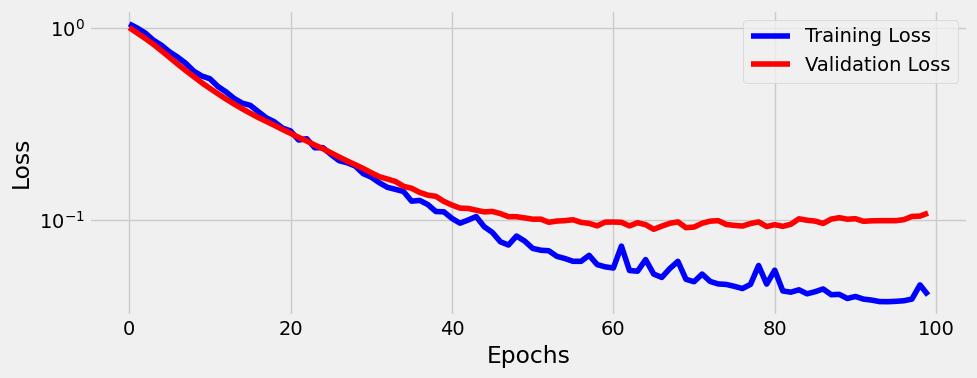

In [13]:
plt.style.use('fivethirtyeight')
def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label='Training Loss', c='b')
    plt.plot(val_losses, label='Validation Loss', c='r')
    plt.yscale('log')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.tight_layout()
    return fig

fig=plot_losses()

In [14]:
def correct(model, test_loader):
        predicteds = []
        ylabels = []
        for x, y in test_loader:
                model.eval()
                yhat = model(x)
                predicted = torch.argmax(yhat, dim=1).detach().numpy()
                predicteds.extend(predicted)
                ylabels.extend(y.detach().numpy())
        return predicteds, ylabels
        

In [15]:
predicteds, ylabels = correct(model, test_loader)

In [16]:
print(predicteds)
print(ylabels)

[np.int64(1), np.int64(2), np.int64(2), np.int64(2), np.int64(0), np.int64(2), np.int64(0), np.int64(2), np.int64(1), np.int64(2), np.int64(2), np.int64(2), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(2), np.int64(0), np.int64(0), np.int64(2), np.int64(1), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(2), np.int64(0), np.int64(0)]
[np.int64(1), np.int64(2), np.int64(2), np.int64(2), np.int64(0), np.int64(2), np.int64(0), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(2), np.int64(1), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(2), np.int64(0), np.int64(0)]


In [17]:
sum = 0
for i in range(len(predicteds)):
        if predicteds[i] == ylabels[i]:
            sum += 1

print(sum/len(predicteds))

0.9333333333333333
